# Olist E-Commerce: Exploratory Data Analysis & Business Insights

This notebook performs an exploratory data analysis (EDA) on the Brazilian E-Commerce dataset (Olist), exploring sales trends, geographic concentration, logistics SLA performance, and customer retention dynamics to prepare data for our SQL Server data warehouse.

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

DATA_DIR = os.path.join('..', 'data', 'raw')

## 1. Dataset Overview & Schema
Inspecting record counts, column counts, and disk usage across all 8 relational tables.

In [3]:
summary = []
for p in sorted(glob.glob(os.path.join(DATA_DIR, '*.csv'))):
    name = os.path.basename(p)
    # Exact dataframe length to properly handle multiline text in reviews
    df_temp = pd.read_csv(p)
    rows = len(df_temp)
    cols = len(df_temp.columns)
    size = os.path.getsize(p) / (1024 * 1024)
    summary.append({'Dataset': name, 'Rows': f'{rows:,}', 'Columns': cols, 'Size (MB)': f'{size:.2f}'})

summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))

                              Dataset    Rows  Columns Size (MB)
          olist_customers_dataset.csv  99,441        5      8.62
        olist_order_items_dataset.csv 112,650        7     14.72
     olist_order_payments_dataset.csv 103,886        5      5.51
      olist_order_reviews_dataset.csv  99,224        7     13.78
             olist_orders_dataset.csv  99,441        8     16.84
           olist_products_dataset.csv  32,951        9      2.27
            olist_sellers_dataset.csv   3,095        4      0.17
product_category_name_translation.csv      73        2      0.00


## 2. Monthly Order Volume & Growth Trends
Tracking order trajectory from late 2016 through mid 2018.

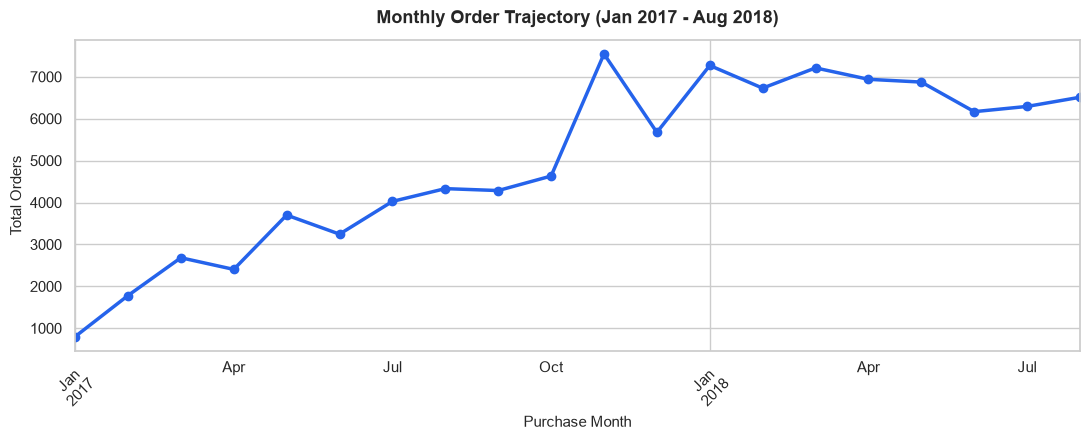

In [5]:
orders = pd.read_csv(os.path.join(DATA_DIR, 'olist_orders_dataset.csv'))
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

# Filter out incomplete months at edges (keep 2017-01 to 2018-08)
valid_orders = orders[(orders['order_purchase_timestamp'] >= '2017-01-01') & (orders['order_purchase_timestamp'] <= '2018-08-31')].copy()
valid_orders['year_month'] = valid_orders['order_purchase_timestamp'].dt.to_period('M')
monthly_orders = valid_orders.groupby('year_month').size()

fig, ax = plt.subplots(figsize=(11, 4.5))
monthly_orders.plot(kind='line', marker='o', color='#2563EB', linewidth=2.5, markersize=6, ax=ax)
ax.set_title('Monthly Order Trajectory (Jan 2017 - Aug 2018)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Purchase Month', fontsize=11)
ax.set_ylabel('Total Orders', fontsize=11)
ax.annotate('Black Friday 2017 Peak\n(7,544 orders)', xy=(10, 7544), xytext=(8, 6500),
            arrowprops=dict(facecolor='#DC2626', shrink=0.08, width=1.5, headwidth=7),
            fontweight='semibold', color='#DC2626')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Key Finding:** Rapid growth throughout 2017, peaking sharply during Black Friday in November 2017, followed by a stabilized plateau around ~6,500 - 7,000 orders/month in 2018.

## 3. Geographic Concentration of Customers
Identifying the top consumer states across Brazil.

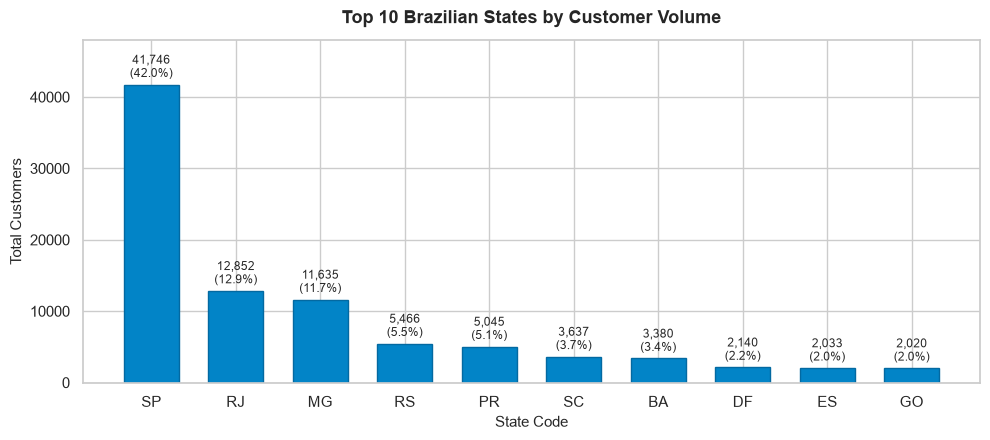

In [8]:
customers = pd.read_csv(os.path.join(DATA_DIR, 'olist_customers_dataset.csv'))
top_states = customers['customer_state'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(top_states.index, top_states.values, color='#0284C7', edgecolor='#0369A1', width=0.65)
ax.set_title('Top 10 Brazilian States by Customer Volume', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('State Code', fontsize=11)
ax.set_ylabel('Total Customers', fontsize=11)

for bar in bars:
    height = bar.get_height()
    pct = (height / len(customers)) * 100
    ax.annotate(f'{height:,}\n({pct:.1f}%)', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8.5)

ax.set_ylim(0, top_states.max() * 1.15)
plt.tight_layout()
plt.show()

**Key Finding:** Extreme geographic concentration. São Paulo (SP) alone accounts for **41.9%** of all customers, followed by Rio de Janeiro (RJ: 12.9%) and Minas Gerais (MG: 11.7%). The Southeast region represents over **65%** of Olist's business.

## 4. Top Product Categories
Translating categories from Portuguese to English and examining top sellers.

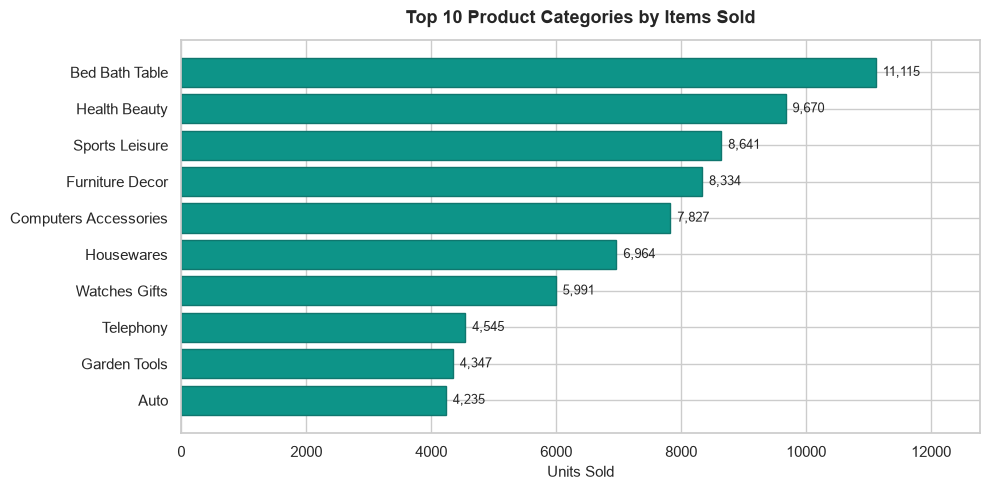

In [11]:
products = pd.read_csv(os.path.join(DATA_DIR, 'olist_products_dataset.csv'))
order_items = pd.read_csv(os.path.join(DATA_DIR, 'olist_order_items_dataset.csv'))
trans = pd.read_csv(os.path.join(DATA_DIR, 'product_category_name_translation.csv'))

prod_full = products.merge(trans, on='product_category_name', how='left')
prod_full['category_english'] = prod_full['product_category_name_english'].fillna('Other / Unknown')
prod_full['category_english'] = prod_full['category_english'].str.replace('_', ' ').str.title()

items_with_prod = order_items.merge(prod_full[['product_id', 'category_english']], on='product_id', how='left')
top_cats = items_with_prod['category_english'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(top_cats.index[::-1], top_cats.values[::-1], color='#0D9488', edgecolor='#0F766E')
ax.set_title('Top 10 Product Categories by Items Sold', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Units Sold', fontsize=11)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f'{w:,}', xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords='offset points', ha='left', va='center', fontsize=9)

ax.set_xlim(0, top_cats.max() * 1.15)
plt.tight_layout()
plt.show()

**Key Finding:** `Bed Bath Table` (11,115 items), `Health Beauty` (9,670 items), and `Sports Leisure` (8,641 items) are the three flagship volume drivers.

## 5. Payment Preferences
Analyzing payment instruments utilized by customers.

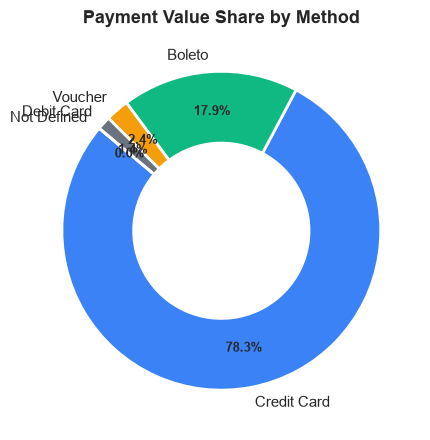

In [14]:
payments = pd.read_csv(os.path.join(DATA_DIR, 'olist_order_payments_dataset.csv'))
pay_summary = payments.groupby('payment_type').agg(
    transaction_count=('order_id', 'count'),
    total_value=('payment_value', 'sum')
).reset_index()
pay_summary['value_pct'] = (pay_summary['total_value'] / pay_summary['total_value'].sum()) * 100
pay_summary = pay_summary.sort_values(by='total_value', ascending=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ['#3B82F6', '#10B981', '#F59E0B', '#6B7280', '#EF4444']
wedges, texts, autotexts = ax.pie(
    pay_summary['total_value'], 
    labels=pay_summary['payment_type'].str.replace('_', ' ').str.title(),
    autopct='%1.1f%%', 
    startangle=140,
    colors=colors[:len(pay_summary)],
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='w', linewidth=2)
)
plt.setp(autotexts, size=9.5, weight='bold')
ax.set_title('Payment Value Share by Method', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Key Finding:** Credit cards account for **78.3%** of transaction volume, followed by Boleto (voucher bank slips) at **17.8%**. Offline voucher/Boleto payments represent a meaningful segment typical of Brazilian e-commerce.

## 6. Delivery SLA Performance vs. Customer Satisfaction
Measuring the direct relationship between logistics delay and customer review ratings.

Avg Score (On-Time): 4.29 / 5.0
Avg Score (Late):    2.27 / 5.0
1-Star Review Rate for Late Orders: 53.7%


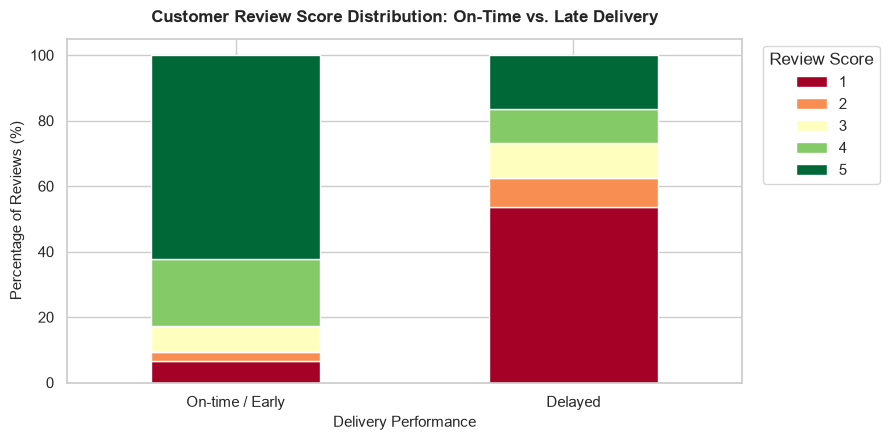

In [17]:
reviews = pd.read_csv(os.path.join(DATA_DIR, 'olist_order_reviews_dataset.csv'))

# Calculate delivery delay relative to estimated date (Day level)
delivered = orders[orders['order_status'] == 'delivered'].copy()
delivered['order_delivered_customer_date'] = pd.to_datetime(delivered['order_delivered_customer_date'])
delivered['order_estimated_delivery_date'] = pd.to_datetime(delivered['order_estimated_delivery_date'])
delivered = delivered.dropna(subset=['order_delivered_customer_date', 'order_estimated_delivery_date'])

delivered['delay_days'] = (delivered['order_delivered_customer_date'].dt.floor('D') - delivered['order_estimated_delivery_date'].dt.floor('D')).dt.days
delivered['is_late'] = delivered['delay_days'] > 0

deliv_rev = delivered.merge(reviews[['order_id', 'review_score']], on='order_id')

# Breakdown of review scores
score_comp = pd.crosstab(deliv_rev['is_late'], deliv_rev['review_score'], normalize='index') * 100
score_comp.index = ['On-time / Early', 'Delayed']

fig, ax = plt.subplots(figsize=(9, 4.5))
score_comp.plot(kind='bar', stacked=True, colormap='RdYlGn', edgecolor='white', ax=ax)
ax.set_title('Customer Review Score Distribution: On-Time vs. Late Delivery', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Delivery Performance', fontsize=11)
ax.set_ylabel('Percentage of Reviews (%)', fontsize=11)
ax.legend(title='Review Score', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

avg_ontime = deliv_rev[~deliv_rev['is_late']]['review_score'].mean()
avg_late = deliv_rev[deliv_rev['is_late']]['review_score'].mean()
late_1star = (deliv_rev[deliv_rev['is_late']]['review_score'] == 1).mean() * 100

print(f'Avg Score (On-Time): {avg_ontime:.2f} / 5.0')
print(f'Avg Score (Late):    {avg_late:.2f} / 5.0')
print(f'1-Star Review Rate for Late Orders: {late_1star:.1f}%')

**Key Finding:** Delivering late is catastrophic to customer satisfaction. On-time orders average **4.29 stars**, whereas late deliveries plunge to **2.27 stars**, with **53.7%** of delayed orders receiving a punishing 1-star review.

## 7. Customer Retention & Repeat Purchase Audit
Evaluating individual customer lifetime behavior via `customer_unique_id`.

In [20]:
cust_counts = customers.groupby('customer_unique_id').size()
total_unique = len(cust_counts)
repeat_cust = (cust_counts >= 2).sum()
onetime_cust = (cust_counts == 1).sum()

print(f'Total Unique Human Customers:    {total_unique:,}')
print(f'Repeat Customers (>= 2 orders):  {repeat_cust:,} ({repeat_cust / total_unique * 100:.2f}%)')
print(f'One-Time Purchasers (= 1 order): {onetime_cust:,} ({onetime_cust / total_unique * 100:.2f}%)')

Total Unique Human Customers:    96,096
Repeat Customers (>= 2 orders):  2,997 (3.12%)
One-Time Purchasers (= 1 order): 93,099 (96.88%)


**Key Finding:** 96.88% of customers (93,099 individuals) only transact once, while only 3.12% (2,997 customers) purchase two or more times. This underlines why **Cohort Retention Analysis** and **RFM Customer Segmentation** are critical business priorities for Olist.